In [1]:
import pandas as pd
import numpy as np
from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

### 1. Analyze motifs per class

In [2]:
OUT_DIR = Path("results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")

In [3]:
file_name = OUT_DIR / "expl_attributes_object_motif_comparison_top0p050.csv"
df = pd.read_csv(file_name)
df

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,"((86, 92), (92, 47))",3,0,0.000000,1,1,1.0,1.0
1,"((0, 5), (0, 43))",5,0,0.000000,1,1,1.0,1.0
2,"((87, 0), (87, 36))",9,0,0.000000,1,1,1.0,1.0
3,"((92, 110), (110, 65))",1,0,0.000000,1,1,1.0,1.0
4,"((100, 5), (109, 5))",12,0,0.000000,1,1,1.0,1.0
...,...,...,...,...,...,...,...,...
4335,"((112, 74), (112, 80))",21,1,0.047619,0,0,NaN,NaN
4336,"((112, 76), (113, 112))",3,1,0.333333,0,0,NaN,NaN
4337,"((112, 78), (113, 112))",4,1,0.250000,0,0,NaN,NaN
4338,"((112, 109), (112, 113))",8,1,0.125000,0,0,NaN,NaN


In [8]:
human_selected = df["human_selected"] > 0
machine_selected = df["machine_selected"] > 0

human_only = (human_selected & ~machine_selected).sum()
machine_only = (~human_selected & machine_selected).sum()
shared = (human_selected & machine_selected).sum()

total = (human_selected | machine_selected).sum()

print(f"TOtal unique selected motifs: {total}")
print(f"Human only: {human_only}")
print(f"Machine only: {machine_only}")
print(f"Shared: {shared}")

TOtal unique selected motifs: 4340
Human only: 3639
Machine only: 685
Shared: 16


In [4]:
fwords_df = pd.read_csv(r"data\function_words_277.csv")
fwords = fwords_df["word"].tolist()

In [5]:
df["motif_fwords"] = df["motif"].apply(
    lambda m: motif_to_fwords(m, fwords)
)

In [6]:
df

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,motif_fwords
0,"((86, 92), (92, 47))",3,0,0.000000,1,1,1.0,1.0,"(hence, herein) (herein, but)"
1,"((0, 5), (0, 43))",5,0,0.000000,1,1,1.0,1.0,"(a, afterwards) (a, besides)"
2,"((87, 0), (87, 36))",9,0,0.000000,1,1,1.0,1.0,"(her, a) (her, been)"
3,"((92, 110), (110, 65))",1,0,0.000000,1,1,1.0,1.0,"(herein, inside) (inside, enough)"
4,"((100, 5), (109, 5))",12,0,0.000000,1,1,1.0,1.0,"(him, afterwards) (indeed, afterwards)"
...,...,...,...,...,...,...,...,...,...
4335,"((112, 74), (112, 80))",21,1,0.047619,0,0,NaN,NaN,"(into, few) (into, further)"
4336,"((112, 76), (113, 112))",3,1,0.333333,0,0,NaN,NaN,"(into, for) (is, into)"
4337,"((112, 78), (113, 112))",4,1,0.250000,0,0,NaN,NaN,"(into, formerly) (is, into)"
4338,"((112, 109), (112, 113))",8,1,0.125000,0,0,NaN,NaN,"(into, indeed) (into, is)"


In [7]:
h = df[
    (df["human_selected"] > 0) &
    (df["machine_selected"] == 0)
]

m = df[
    (df["human_selected"] == 0) &
    (df["machine_selected"] > 0)
]

print("Human-only motifs selected once:",
      (h["human_selected"] == 1).sum())

print("Machine-only motifs selected once:",
      (m["machine_selected"] == 1).sum())

Human-only motifs selected once: 3596
Machine-only motifs selected once: 681


In [9]:
motif_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\expl_attributes_object_motif_2edges_top_0p050.pth",
    map_location="cpu",
    weights_only=False
)

In [10]:
print(type(motif_results))

<class 'list'>


In [11]:
df_graphs = pd.DataFrame(motif_results)
df_graphs

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((41, 5), (42, 41)), ((41, 5), (47, 5)), ((41...",9
1,17,0,0,"[((8, 101), (77, 8)), ((10, 80), (80, 38)), ((...",16
2,20,0,0,"[((5, 101), (10, 101)), ((5, 101), (42, 5)), (...",18
3,22,0,0,"[((2, 61), (2, 109)), ((2, 61), (5, 2)), ((2, ...",9
4,28,0,0,"[((0, 97), (97, 101)), ((0, 97), (109, 0)), ((...",16
...,...,...,...,...,...
355,2372,1,1,[],0
356,2379,1,1,"[((28, 80), (28, 92)), ((28, 80), (75, 28)), (...",5
357,2381,1,1,"[((3, 56), (37, 56)), ((7, 0), (7, 92)), ((7, ...",7
358,2383,1,1,"[((5, 61), (24, 61)), ((5, 61), (43, 5)), ((5,...",7


In [13]:
df_graphs = df_graphs[
    df_graphs["label"] == df_graphs["pred"]
]

df_graphs["class"] = df_graphs["label"].map({
    0: "Human",
    1: "Machine"
})

display(
    df_graphs.groupby("class")["num_motifs"].agg(
        ["count", "sum", "mean", "median", "min", "max"]
    )
)

,count,sum,mean,median,min,max
class,,,,,,
Human,180,3699,20.550000,16.0,0,91
Machine,178,705,3.960674,3.0,0,14


In [14]:
results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_attributes_object.pth",
    map_location="cpu",
    weights_only=False
)

In [15]:
df_result = pd.DataFrame(results)
df_result

,row,label,pred,prob_machine,x,edge_index,edge_weight,edge_mask,node_mask
0,13,0,0,4.222530e-04,"[[tensor(1.6094), tensor(1.6064), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0831), tensor(0.2308), tensor(0.1477...","[tensor(0.), tensor(0.1271), tensor(0.1271), t...","[[tensor(0.5191), tensor(0.5653), tensor(0.496..."
1,17,0,0,3.552880e-04,"[[tensor(2.4849), tensor(2.8721), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0464), tensor(0.0348), tensor(0.0464...","[tensor(0.), tensor(0.1319), tensor(0.1162), t...","[[tensor(0.5103), tensor(0.4914), tensor(0.300..."
2,20,0,0,8.897103e-06,"[[tensor(2.1972), tensor(2.1108), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0504), tensor(0.1008), tensor(0.4482...","[tensor(0.1209), tensor(0.1279), tensor(0.1162...","[[tensor(0.5122), tensor(0.5484), tensor(0.237..."
3,22,0,0,4.431677e-05,"[[tensor(2.1972), tensor(1.7544), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0320), tensor(0.0320), tensor(0.0320...","[tensor(0.1165), tensor(0.1229), tensor(0.1141...","[[tensor(0.5148), tensor(0.4713), tensor(0.342..."
4,28,0,0,8.057309e-07,"[[tensor(3.1355), tensor(4.3222), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0387), tensor(0.0145), tensor(0.0533...","[tensor(0.), tensor(0.1227), tensor(0.1355), t...","[[tensor(0.3736), tensor(0.4347), tensor(0.127..."
...,...,...,...,...,...,...,...,...,...
355,2372,1,1,9.887499e-01,"[[tensor(0.6931), tensor(0.8000), tensor(-0.27...","[[tensor(0), tensor(1), tensor(5), tensor(5), ...","[tensor(1.), tensor(1.), tensor(0.0765), tenso...","[tensor(0.0832), tensor(0.0834), tensor(0.0857...","[[tensor(0.2207), tensor(0.2274), tensor(0.144..."
356,2379,1,1,9.874618e-01,"[[tensor(1.6094), tensor(1.6667), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.1062), tensor(0.1416), tensor(0.1062...","[tensor(0.1043), tensor(0.1006), tensor(0.1078...","[[tensor(0.3840), tensor(0.3813), tensor(0.177..."
357,2381,1,1,9.999725e-01,"[[tensor(1.9459), tensor(1.6949), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.1343), tensor(0.3134), tensor(0.2388...","[tensor(0.), tensor(0.1086), tensor(0.1121), t...","[[tensor(0.3553), tensor(0.3131), tensor(0.165..."
358,2383,1,1,9.999624e-01,"[[tensor(0.6931), tensor(0.2653), tensor(-0.27...","[[tensor(0), tensor(1), tensor(1), tensor(1), ...","[tensor(1.), tensor(0.2994), tensor(0.1684), t...","[tensor(0.0983), tensor(0.0996), tensor(0.1048...","[[tensor(0.1424), tensor(0.1242), tensor(0.125..."


In [16]:
edge_masks = df_result["edge_mask"]
edge_masks

0      [tensor(0.), tensor(0.1271), tensor(0.1271), t...
1      [tensor(0.), tensor(0.1319), tensor(0.1162), t...
2      [tensor(0.1209), tensor(0.1279), tensor(0.1162...
3      [tensor(0.1165), tensor(0.1229), tensor(0.1141...
4      [tensor(0.), tensor(0.1227), tensor(0.1355), t...
                             ...                        
355    [tensor(0.0832), tensor(0.0834), tensor(0.0857...
356    [tensor(0.1043), tensor(0.1006), tensor(0.1078...
357    [tensor(0.), tensor(0.1086), tensor(0.1121), t...
358    [tensor(0.0983), tensor(0.0996), tensor(0.1048...
359    [tensor(0.0939), tensor(0.0999), tensor(0.1050...
Name: edge_mask, Length: 360, dtype: object

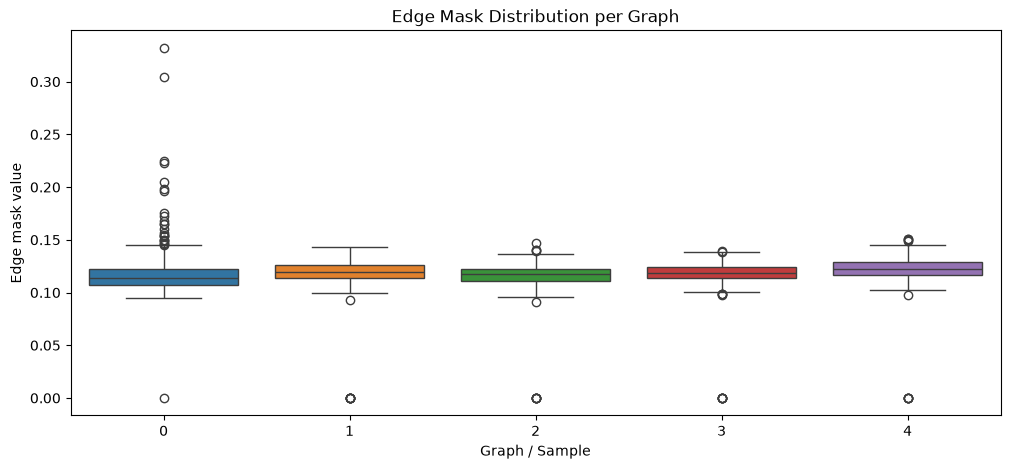

In [17]:
mask_values = [
    t.detach().cpu().numpy().flatten()
    for t in edge_masks
]

plt.figure(figsize=(12, 5))

sns.boxplot(data=mask_values[:5])

plt.xlabel("Graph / Sample")
plt.ylabel("Edge mask value")
plt.title("Edge Mask Distribution per Graph")

plt.show()

In [18]:
rows = []

for result in results:

    if result["label"] != result["pred"]:
        continue

    edge_index = result["edge_index"]

    num_edges = (edge_index[0] != edge_index[1]).sum().item()

    rows.append({
        "class": "Human" if result["label"] == 0 else "Machine",
        "num_edges": num_edges
    })

df_edges = pd.DataFrame(rows)

display(
    df_edges.groupby("class")["num_edges"].agg(
        ["count", "mean", "median", "min", "max"]
    )
)

,count,mean,median,min,max
class,,,,,
Human,180,364.477778,331.0,122,895
Machine,178,160.410112,160.5,40,325


In [19]:
selected_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\expl_attributes_object_motif_edges_top_0p050.pth",
    map_location="cpu",
        weights_only=False
)

In [20]:
rows = []

for selected, motif_result in zip(selected_results, motif_results):

    if selected["row"] != motif_result["row"]:
        raise ValueError("Graph order does not match")

    if selected["label"] != selected["pred"]:
        continue

    edges = {
        (int(u), int(v))
        for u, v in selected["edge_index"].T.tolist()
        if u != v
    }

    k = len(edges)

    M = motif_result["num_motifs"]

    possible_pairs = math.comb(k, 2)

    interconnectedness = (
        M / possible_pairs
        if possible_pairs > 0 else float("nan")
    )

    rows.append({
        "class": "Human" if selected["label"] == 0 else "Machine",
        "selected_edges": k,
        "num_motifs": M,
        "possible_pairs": possible_pairs,
        "interconnectedness": interconnectedness
    })

df_connectivity = pd.DataFrame(rows)

In [21]:
display(
    df_connectivity.groupby("class")[
        ["selected_edges", "num_motifs", "interconnectedness"]
    ].agg(["mean", "median"])
)

selected_edges        num_motifs        interconnectedness          
                  mean median       mean median               mean    median
class                                                                       
Human        18.677778   17.0  20.550000   16.0           0.110407  0.105338
Machine       8.516854    8.5   3.960674    3.0           0.125743  0.107143

### 2. Analyze words in the motifs per class

In [22]:
def count_function_words(df, column, fwords):
    counts = Counter()

    for _, row in df[df[column] > 0].iterrows():
        motif = row["motif"]

        if isinstance(motif, str):
            motif = ast.literal_eval(motif)

        nodes = {
            node 
            for edge in motif
            for node in edge
        }

        for node in nodes:
            counts[fwords[node]] += 1
            
    return pd.DataFrame(
        counts.most_common(),
        columns=["word", "count"]
    )
    

In [23]:
human_words = count_function_words(df, "human_selected", fwords)
human_words

,word,count
0,herein,696
1,further,673
2,a,474
3,afterwards,449
4,behind,370
...,...,...
99,how,4
100,its,4
101,amoungst,3
102,between,2


In [24]:
machine_words = count_function_words(df, "machine_selected", fwords)
machine_words

,word,count
0,herein,197
1,afterwards,156
2,eg,125
3,further,121
4,from,72
...,...,...
88,did,1
89,heretofore,1
90,already,1
91,any,1


In [25]:
word_comparison = human_words.rename(
    columns={"count": "human_count"}
    ).merge(
        machine_words.rename(
            columns={"count": "machine_count"}
        ),
        on="word",
        how="outer"
    ).fillna(0)

word_comparison["difference"] = (
    word_comparison["human_count"] - word_comparison["machine_count"]
)

word_comparison


,word,human_count,machine_count,difference
0,a,474.0,62.0,412.0
1,about,46.0,22.0,24.0
2,above,73.0,22.0,51.0
3,across,9.0,11.0,-2.0
4,after,73.0,15.0,58.0
...,...,...,...,...
101,inside,16.0,10.0,6.0
102,instead,166.0,8.0,158.0
103,into,229.0,10.0,219.0
104,is,57.0,10.0,47.0


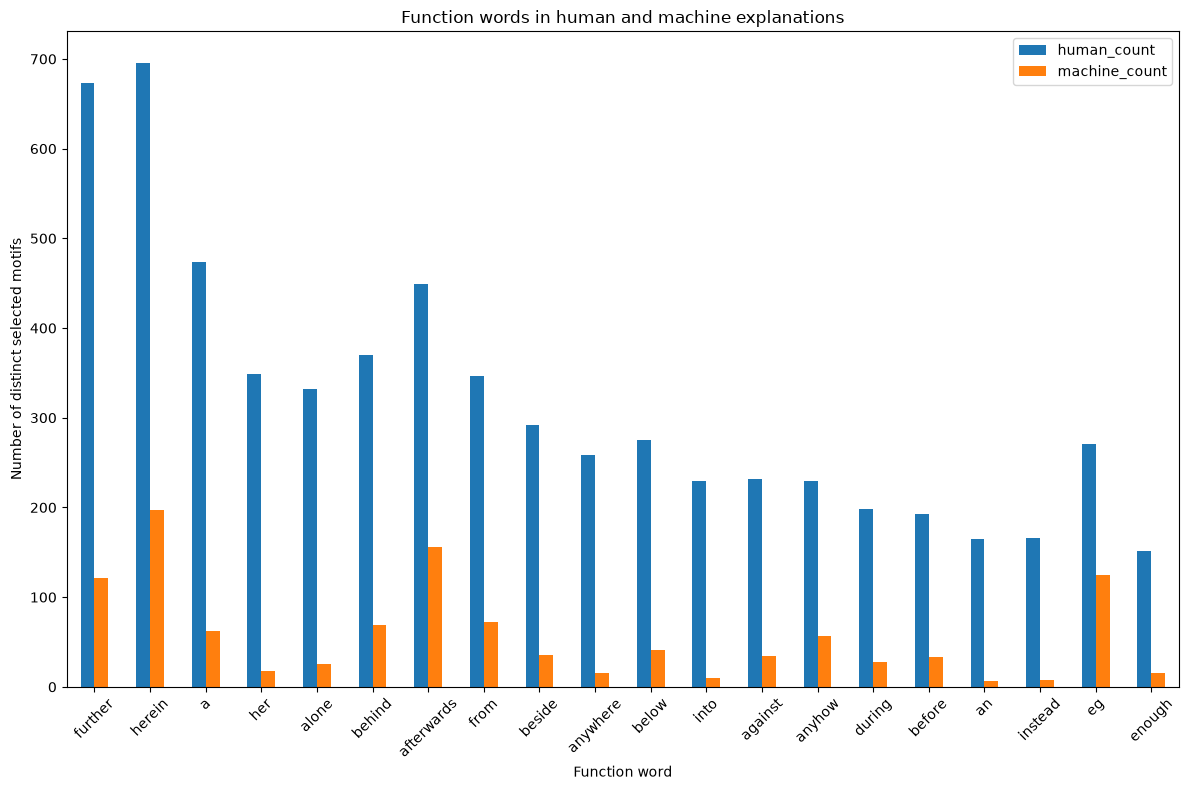

In [26]:
top_words = word_comparison.sort_values(
    "difference",
    key=abs,
    ascending=False
).head(20)

top_words = top_words.set_index("word")

top_words[["human_count", "machine_count"]].plot(
    kind="bar",
    figsize=(12,8)
)

plt.xlabel("Function word")
plt.ylabel("Number of distinct selected motifs")
plt.title("Function words in human and machine explanations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()